In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.optimize import fsolve

In [13]:
def neg_exp(x, A, k, h, c):
    return (A * np.exp(-k * (x - h)) + c)

In [38]:
def neg_exp_inv(y, A, k, h, c):
    return (np.log((y-c)/A)/(-k) + h)

In [ ]:
def lin_exp(x, A, k, h, c):
    return ()

In [54]:
scope_config_label = "15V-33V-1Hz_Out1"
infile_path = scope_config_label + ".csv"
standard_scope_df = pd.read_csv(infile_path, skiprows=15)
time_data = standard_scope_df["TIME"].astype(float)
shutter_vdata = standard_scope_df["CH2"].astype(float)

signal_start_idx = np.argmax(shutter_vdata)
signal_tstart = time_data.iloc[signal_start_idx]
print(signal_tstart)
Ampl = shutter_vdata.max()
print(Ampl)
plateau = shutter_vdata.loc[signal_start_idx+1:].min()
print(plateau)
Ampl -= plateau
print(Ampl)

1.6e-05
13.2
3.6
9.6


In [26]:
p0 = [9.6, 1., 0., 3.6]
popt, pcov = curve_fit(neg_exp, time_data[signal_start_idx+20:], shutter_vdata.loc[signal_start_idx+20:], p0=p0)
A_opt, k_opt, h_opt, c_opt = popt
print(f"Fitted params:\n  A={A_opt:.3f}\n  k={k_opt:.3f}\n  h={h_opt:.3f}\n  c={c_opt:.3f}")


Fitted params:
  A=8.033
  k=331.385
  h=0.000
  c=3.809


In [57]:
e_inv_value = A_opt/np.e + c_opt
print(e_inv_value)
objective = lambda x: neg_exp(x, A_opt, k_opt, h_opt, c_opt) - e_inv_value

initial_guess = 4.0e-3
tau_RC = fsolve(objective, initial_guess)[0]
print(tau_RC)
print(neg_exp_inv(e_inv_value, A_opt, k_opt, h_opt, c_opt))

R_load = 190.

6.764336559482466
0.0035118350523184777
0.0035118350523184244


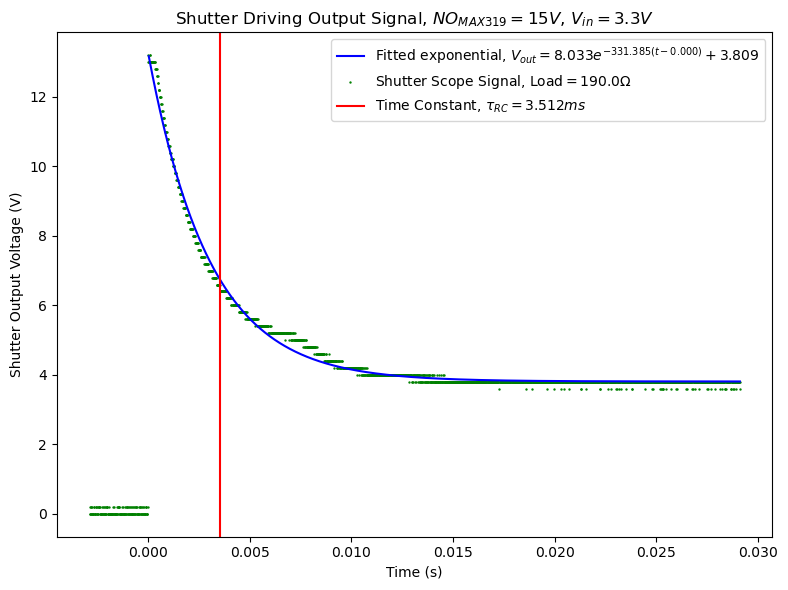

In [58]:
t_data_smooth = np.linspace(time_data.iloc[signal_start_idx+1], time_data.iloc[-1], 10000)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(t_data_smooth, neg_exp(t_data_smooth, A_opt, k_opt, h_opt, c_opt), color="blue", label=f"Fitted exponential, $V_{{out}}={A_opt:.3f}e^{{-{k_opt:.3f}(t-{h_opt:.3f})}}+{c_opt:.3f}$")
ax.scatter(time_data, shutter_vdata, s=0.5, color="green", label=f"Shutter Scope Signal, Load$={R_load}\\Omega$")
ax.axvline(x=tau_RC, color="red", label=f"Time Constant, $\\tau_{{RC}}={tau_RC*1000:.3f}ms$")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Shutter Output Voltage (V)")
ax.set_title("Shutter Driving Output Signal, $NO_{{MAX319}}=15V$, $V_{{in}}=3.3V$")
ax.legend(loc="upper right")
fig.tight_layout()
plt.savefig(scope_config_label + "_fitted.jpg")
plt.show()